# Lab 3c — Local Post-hoc Explainability on Structured Data: SHAP

This lab covers **SHAP (SHapley Additive exPlanations)** for explaining predictions of a black-box classifier on structured data.

### Learning objectives
By the end of the lab, you should be able to:
- build a SHAP explainer with the **modern unified API** (`shap.Explainer`);
- work consistently with a **`shap.Explanation`** object;
- interpret **local** explanations (bar, force, waterfall);
- interpret **global summaries** obtained by aggregating local SHAP values (bar, beeswarm, scatter/dependence);
- distinguish the **base value**, **feature contribution**, and **model output**.


## 🔍 What is SHAP?

SHAP assigns each feature a contribution to a prediction using ideas from **Shapley values** in cooperative game theory.
For one instance, the explanation satisfies the additive decomposition

$$
f(x) = \phi_0 + \sum_{j=1}^{d}\phi_j,
$$

where:
- $\phi_0$ is the **base value** (expected model output under the SHAP background distribution),
- $\phi_j$ is the SHAP contribution of feature \(j\),
- positive/negative values push the selected output respectively above/below the base value.

> **Important:** SHAP values are attributions under a particular masking/background assumption. They are not causal effects.


## ⚙️ Data preparation (~10 min)

We use the **Adult** dataset distributed through `shap.datasets.adult()` and train a Random Forest classifier.
The numeric representation is used by the model, while `display=True` provides readable categorical values for plots.


### ⚙️ Step 1 — Imports


In [ ]:
# If needed in a fresh environment:
# !pip install -U shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

print("SHAP version:", shap.__version__)


SHAP version: 0.54.1


### ⚙️ Step 2 — Load the Adult dataset


In [ ]:
# Model-ready numeric representation
X, y = shap.datasets.adult()

# Human-readable representation of the same rows
X_display, y_display = shap.datasets.adult(display=True)

print("X shape:", X.shape)
X.head()

print("Y shape:", y.shape)
print(y)


X shape: (32561, 12)
Y shape: (32561,)
[False False False ... False False  True]


### ⚙️ Step 3 — Train/test split

> 🔑 **Key reminder:** the test set must remain unseen during model fitting. The SHAP background/masker will also be built from the **training set**, not the test set.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


### ⚙️ Step 4 — Train the black-box classifier


In [ ]:
rf_clf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))


Test accuracy: 0.8524489482573315


### ⚙️ Step 5 — Select data to explain

To keep the lab fast, we explain only a subset of instances. The explanation is still computed **per instance**; later plots aggregate these local explanations.


In [ ]:
sample_data = X_test.iloc[:100].copy()
sample_X_display = X_display.loc[sample_data.index].copy()

print("Number of explained instances:", len(sample_data))


Number of explained instances: 100


## Exercise 1 — Build a SHAP explainer 🧩

We use the modern unified API:

```python
explainer = shap.Explainer(model, masker=masker)
shap_values = explainer(data)
```

The result is a **`shap.Explanation` object**. We will keep this object throughout the notebook instead of switching to the legacy `explainer.shap_values(...)` API.

**Your tasks:**
1. Build an `Independent` masker from the training data.
2. Create `shap.Explainer` using the fitted Random Forest model.
3. Inspect which specialized explainer SHAP selected automatically.


In [ ]:
#### START CODE HERE ####
masker = shap.maskers.Independent(X_train, max_samples=100)
explainer = shap.Explainer(rf_clf, masker=masker)
#### END CODE HERE ####

print("Selected explainer:", type(explainer).__name__)


Selected explainer: TreeExplainer


### 1.2 — Compute SHAP values as an `Explanation`

For a binary classifier, the explanation typically has shape

$
(n_{\text{instances}}, n_{\text{features}}, n_{\text{classes}}).
$

We select one output/class and continue working with that sliced **`Explanation` object**.


In [ ]:
#### START CODE HERE ####
shap_values = explainer(sample_data)

# Explain the positive class (>50K)
class_index = 1
class_names = ["<=50K", ">50K"]
shap_values_class = shap_values[:, :, class_index]
ƒ
# Attach readable feature values for plotting where supported
shap_values_class.display_data = sample_X_display.values
#### END CODE HERE ####

print("Explanation type:", type(shap_values))
print("All outputs shape:", shap_values.values.shape)
print("Selected class shape:", shap_values_class.values.shape)
print("Selected class:", class_names[class_index])


100%|===================| 199/200 [00:58<00:00]       

Explanation type: <class 'shap._explanation.Explanation'>
All outputs shape: (100, 12, 2)
Selected class shape: (100, 12)
Selected class: >50K


### 1.3 — Check the additive decomposition

For an explained instance, SHAP should reconstruct the selected model output:

$$
\text{base value} + \sum_j \text{SHAP}_j \approx f(x).
$$

For this Random Forest explainer, the selected output corresponds to the class probability.


In [ ]:
id_instance = 50

base_value = shap_values_class[id_instance].base_values
contribution_sum = shap_values_class[id_instance].values.sum()
reconstructed = base_value + contribution_sum
model_probability = rf_clf.predict_proba(sample_data.iloc[[id_instance]])[0, class_index]

print("Base value:          ", base_value)
print("Sum of SHAP values:  ", contribution_sum)
print("Reconstructed output:", reconstructed)
print("Model probability:   ", model_probability)


Base value:           0.23287974790755137
Sum of SHAP values:   -0.09287974925818333
Reconstructed output: 0.13999999864936802
Model probability:    0.14


## Exercise 2 — Local explanations 🔎

A local explanation describes **one prediction**. We will inspect the same instance with three complementary plots.

**Your tasks:**
1. Create a local SHAP bar plot.
2. Create a force plot.
3. Create a waterfall plot.
4. Compare what information each visualization emphasizes.


### 2.1 — Local bar plot


Predicted probabilities: [0.86 0.14]


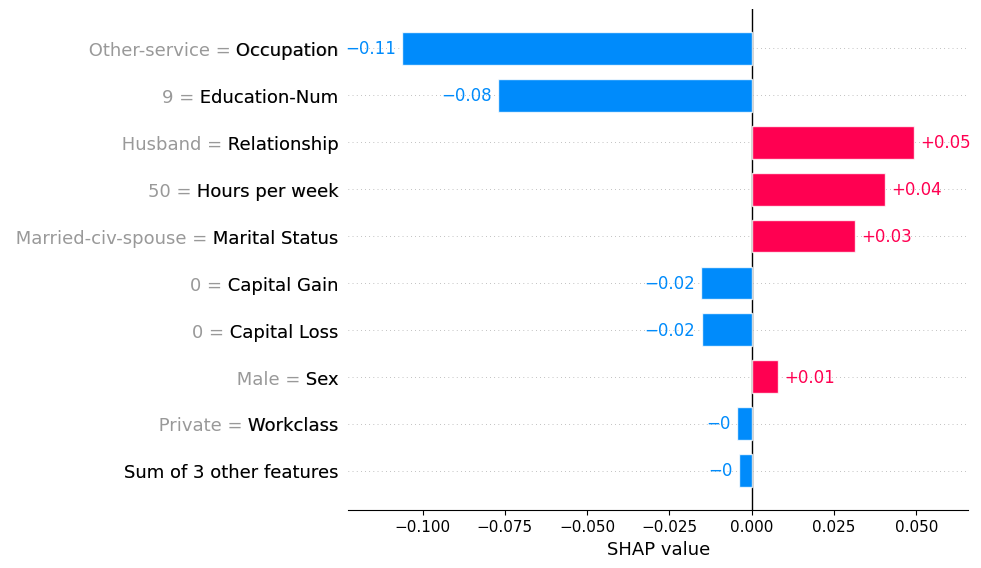

In [ ]:
id_instance = 50

print("Predicted probabilities:", rf_clf.predict_proba(sample_data.iloc[[id_instance]])[0])
shap.plots.bar(shap_values_class[id_instance], max_display=10)


### 2.2 — Force plot

The force plot starts from the **base value** and shows which features push the selected output upward or downward until it reaches the instance prediction.


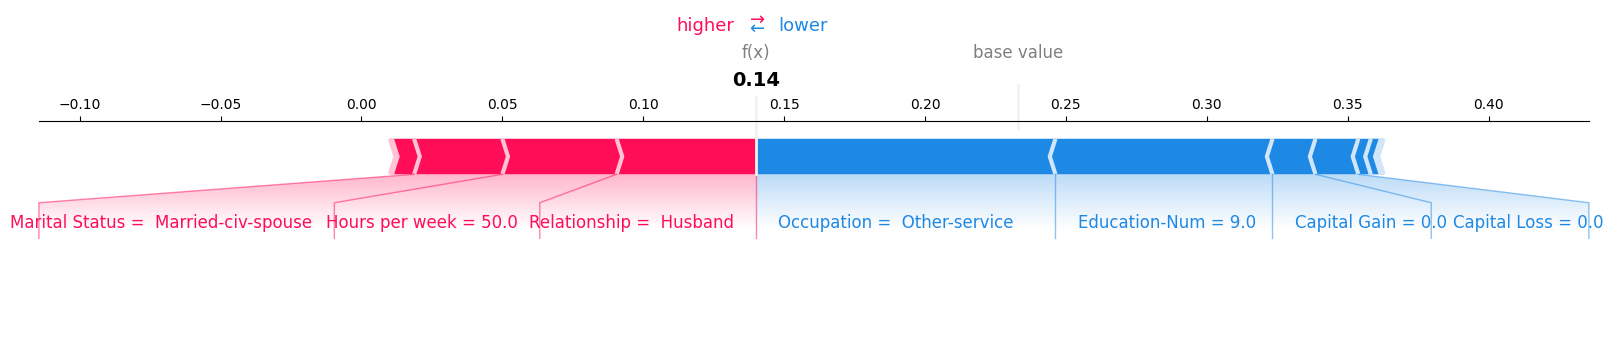

In [ ]:
shap.plots.force(
    shap_values_class[id_instance],
    matplotlib=True
)


### 2.3 — Waterfall plot

The waterfall plot shows the same additive decomposition explicitly: starting from the expected output, feature contributions accumulate until the final model output is reached.


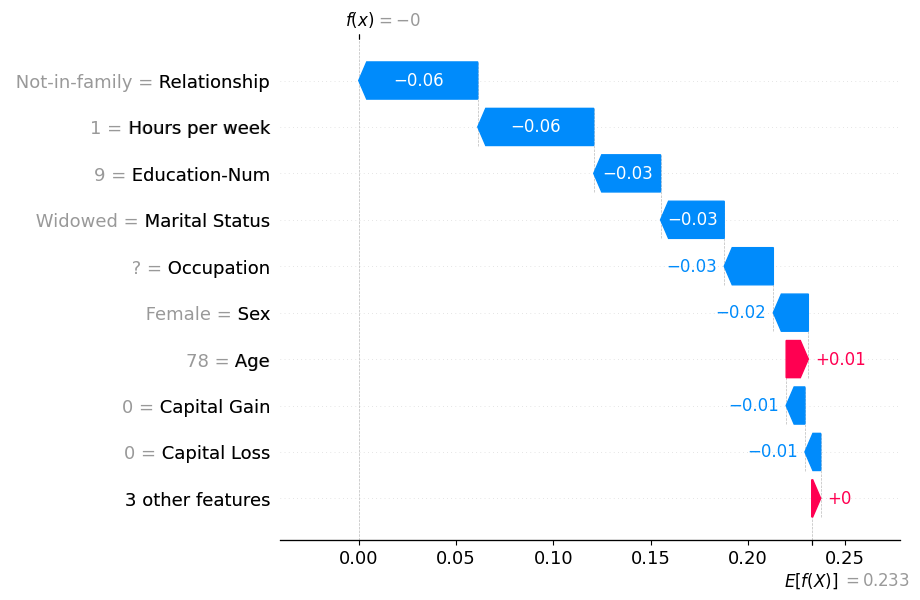

In [ ]:
shap.plots.waterfall(
    shap_values_class[id_instance],
    max_display=10
)


## Exercise 3 — From local explanations to global summaries 🌍

SHAP values are computed locally, but we can aggregate them over many instances to summarize model behaviour.

> **Important:** these plots summarize the explained sample. They are not a causal description of the data-generating process.


### 3.1 — Global feature-importance bar plot

`shap.plots.bar()` applied to multiple rows ranks features using the mean absolute SHAP magnitude across the explained instances.


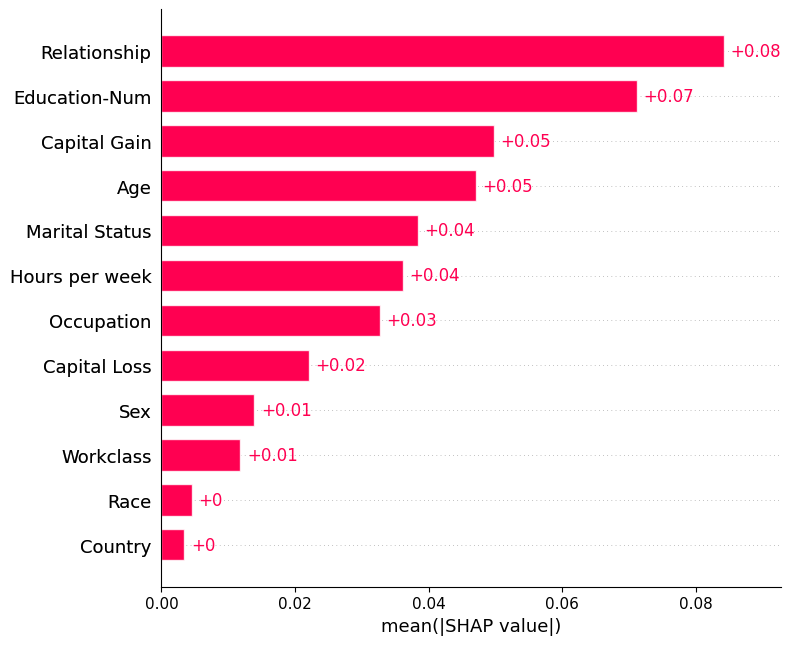

In [ ]:
shap.plots.bar(shap_values_class, max_display=12)


### 3.2 — Beeswarm plot

The beeswarm retains the **distribution and direction** of local contributions rather than collapsing each feature to one mean absolute value.


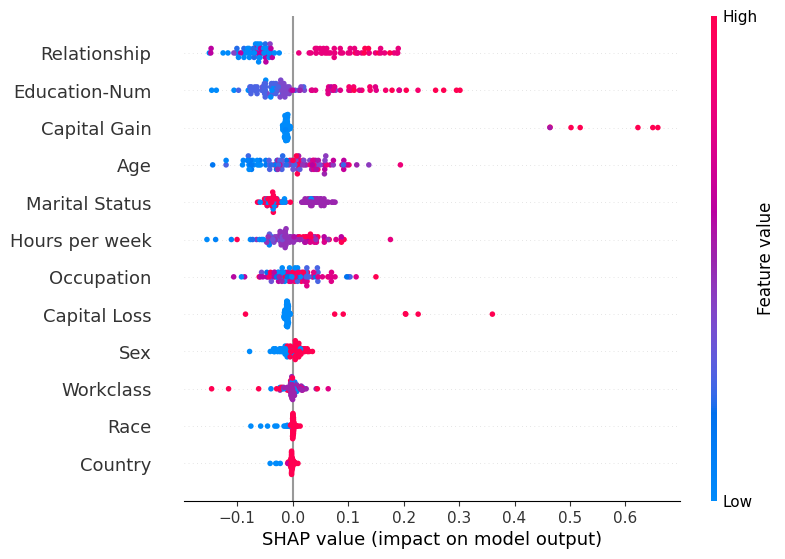

In [ ]:
shap.plots.beeswarm(shap_values_class, max_display=12)


### 3.3 — SHAP scatter / dependence plots

For a selected feature, the x-axis is the feature value and the y-axis is its SHAP contribution. Coloring by the full explanation can reveal potential interactions with other features.


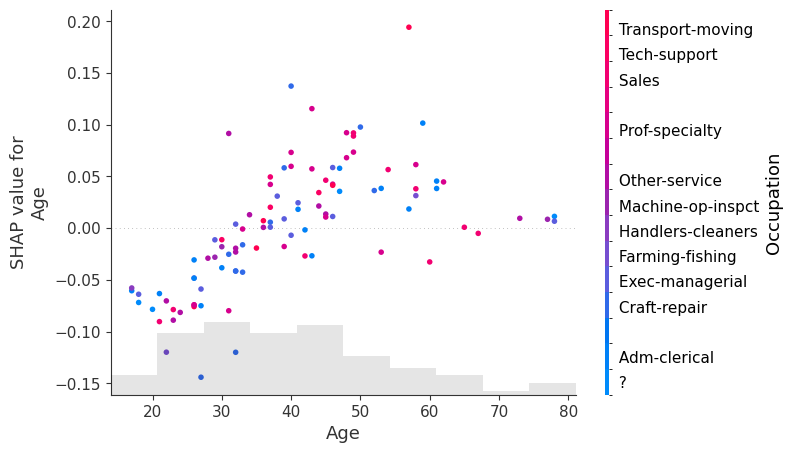

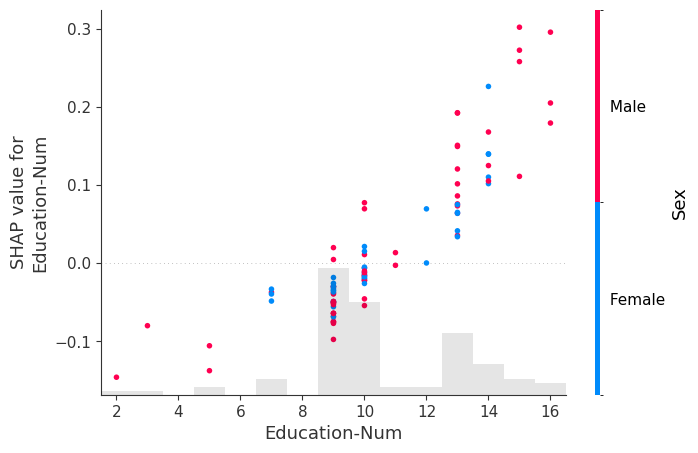

In [ ]:
selected_features = ["Age", "Education-Num"]

for feature_name in selected_features:
    shap.plots.scatter(
        shap_values_class[:, feature_name],
        color=shap_values_class
    )


### 3.4 — Force plot for multiple instances

The interactive multi-instance force plot lets you inspect how local attributions vary across a small set of observations.


In [ ]:
shap.plots.force(shap_values_class[:10])


### 🔍 Reflection Questions

1. **Base value vs prediction:** What does the SHAP base value represent? How do the individual feature contributions recover the model output for one instance?

2. **Local vs global:** Why is a large SHAP value for one individual not evidence that the same feature is globally important for every instance?

3. **Feature dependence:** What problem arises when correlated features are treated as independently maskable? How should this affect your interpretation of the attribution?

4. **Explainer choice:** Why is a tree-specific SHAP algorithm preferable to a fully model-agnostic method for a Random Forest when both are applicable?


### ✅ Suggested answers to the reflection questions

1. **Base value vs prediction.** The base value is the expected selected model output under the explainer's background distribution. For one instance, adding all SHAP contributions to that base value reconstructs the selected model output (up to numerical precision).

2. **Local vs global.** A SHAP value is conditional on the instance and on the coalition/masking context. A feature can strongly influence one prediction but have little effect elsewhere. Global SHAP plots aggregate many local explanations; they should not be inferred from a single case.


3. **Feature dependence.** Independent masking can create unrealistic feature combinations when predictors are correlated. Credit may then be distributed in a way that depends on the masking assumption. SHAP values should therefore be interpreted as model attributions under the chosen feature-dependence semantics, not as causal effects.

4. **Explainer choice.** Tree-aware SHAP exploits the structure of the Random Forest and computes attributions much more efficiently than generic perturbation-based methods. A model-agnostic method is useful when model internals are unavailable, but it generally requires many more model evaluations.


## ⭐ Optional — Compare with a model-specific SHAP explainer

* Redo your analysis with KernelExplainer or another Explainer
* Use a callable prediction function instead of the Random Forest object and inspect which explainer `shap.Explainer` selects. Compare:
  * computation time (hint: use colab magic command %%timeit)
  * output shape;
  * qualitative agreement of the most important features;
  * why algorithm-specific explainers can be substantially faster.
